In [19]:
from typing import List

import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl


In [20]:
class NeuralNetworkException(Exception):
    def __init__(self, msg):
        self.messege = msg
    def get_message(self):
        return self.messege

class NeuralNetwork:


    @staticmethod
    def relu(x: np.ndarray)->np.ndarray:
        return np.maximum(x,0)
    @staticmethod
    def relu_derivative(x: np.ndarray)->np.ndarray:
        return np.where(x>0,1.0,0)


    def __init__(self, initial_input_size):
        self.layers: list[tuple] = list()
        self.initial_input_size = initial_input_size
        self.last_layer_input_size = initial_input_size

    def add_layer(self, neuron_count, weight_min_value=None, weight_max_value=None, weights: np.ndarray|None=None, activation_function=None, derivative_function=None):
        if weights is None and weight_min_value is None and weight_max_value is None:
            raise NeuralNetworkException("Bad arguments")
        if weights is None:
            weights = np.random.uniform(weight_min_value, weight_max_value, (neuron_count, self.last_layer_input_size))

        given_neuron_count, input_size = weights.shape
        if input_size != self.last_layer_input_size:
            raise NeuralNetworkException("weights inputs size does not match last layer input size")

        self.layers.append((weights, activation_function, derivative_function))
        self.last_layer_input_size = neuron_count


    def save_model(self, filename: str):
        weights_dict = {}

        activ_names = []
        deriv_names = []

        for i, (weights, activ_func, deriv_func) in enumerate(self.layers):
            weights_dict[f'layer_{i}_weights'] = weights

            activ_names.append(activ_func.__name__ if activ_func is not None else "None")
            deriv_names.append(deriv_func.__name__ if deriv_func is not None else "None")

        np.savez(filename,
                 activ_funcs=np.array(activ_names, dtype=str),
                 deriv_funcs=np.array(deriv_names, dtype=str),
                 initial_input_size=np.array([self.initial_input_size]),
                 last_layer_input_size=np.array([self.last_layer_input_size]),
                 **weights_dict)


    def load_model(self, filename: str):
        data = np.load(filename)

        function_registry = {
            'relu': self.relu,
            'relu_derivative': self.relu_derivative,
            'None': None
        }

        activ_names = data['activ_funcs']
        deriv_names = data['deriv_funcs']

        self.initial_input_size = data['initial_input_size'][0]
        self.last_layer_input_size = data['last_layer_input_size'][0]

        self.layers = []

        for i in range(len(activ_names)):
            weights = data[f'layer_{i}_weights']

            activ_func = function_registry[activ_names[i]]
            deriv_func = function_registry[deriv_names[i]]

            self.layers.append((weights, activ_func, deriv_func))


    def predict(self, x: np.ndarray | None):
        if x is None:
            raise NeuralNetworkException("Bad arguments")
        if x.shape[0] != self.initial_input_size:
            raise NeuralNetworkException("Input len does not match required input size")

        output = x
        for layer_weights, activ_func, _ in self.layers:
            if output.shape[0] != layer_weights.shape[1]:
                raise NeuralNetworkException("Bad layer and input dimensions")

            output = np.dot(layer_weights, output)

            if activ_func is not None:
                output = activ_func(output)

        return output

    def fit(self, x: np.ndarray | None, y: np.ndarray | None, learning_rate: float) -> float:
        if x is None or y is None:
            raise NeuralNetworkException("Bad arguments")

        activations = [x]
        current_activation = x

        for layer_weights, activ_func, _ in self.layers:
            z = np.dot(layer_weights, current_activation)

            if activ_func is not None:
                current_activation = activ_func(z)
            else:
                current_activation = z

            activations.append(current_activation)

        error = np.subtract(current_activation, y)
        loss = float(np.mean(np.square(error)))
        #mse
        current_error_signal = np.multiply(error, 2.0 / current_activation.shape[0])

        for l in reversed(range(len(self.layers))):

            layer_weights, activ_func, deriv_func = self.layers[l]

            if deriv_func is not None:
                current_error_signal = np.multiply(current_error_signal, deriv_func(activations[l+1]))

            delta_weights = np.outer(current_error_signal, activations[l])


            if l > 0:
                current_error_signal = np.dot(layer_weights.T, current_error_signal)

            new_weights = np.subtract(layer_weights, np.multiply(delta_weights, learning_rate))
            self.layers[l] = (new_weights, activ_func, deriv_func)

        return loss




In [36]:
x_input= np.array([[0.5,0.1,0.2,0.8],
    [0.75,0.3,0.1,0.9],
    [0.1,0.7,0.6,0.2]])

y_expected = np.array([[0.1,0.5,0.1,0.7],
                       [1.0,0.2,0.3,0.6],
                       [0.1,-0.5,0.2,0.2]
                       ])

Wh = np.array([
    [0.1,0.1,-0.3],
    [0.1,0.2,0.0],
    [0.0,0.7,0.1],
    [0.2,0.4,0.0],
    [-0.3,0.5,0.1]
])
Wy = np.array([
    [0.7,0.9,-0.4,0.8,0.1],
    [0.8,0.5,0.3,0.1,0.0],
    [-0.3,0.9,0.3,0.1,-0.2]
])

alpha = 0.01


ReLu_model = NeuralNetwork(initial_input_size = 3)
ReLu_model.add_layer(5,weights=Wh,activation_function=NeuralNetwork.relu,derivative_function=NeuralNetwork.relu_derivative)
ReLu_model.add_layer(3,weights=Wy,activation_function=None,derivative_function=None)


epoch_count = 50
stop_epochs = [0,49]
for epoch_number in range(epoch_count):
    if epoch_number in stop_epochs:
        print(f"Oczekiwane wynik w {epoch_number+1} epoce:\n")

    total_loss = 0
    for i in range(x_input.shape[1]):
        series_x = x_input[:, i]

        out = ReLu_model.predict(series_x)
        epoch_loss = ReLu_model.fit(x = series_x, y = y_expected[:, i], learning_rate = alpha)
        if epoch_number in stop_epochs:
            print(f" * wyjście sieci po {i+1} serii - output = \n{out.reshape(-1, 1)}\n")
            total_loss += epoch_loss

    if epoch_number in stop_epochs:
        print(f"totalny loss: {total_loss}")



Oczekiwane wynik w 1 epoce:

 * wyjście sieci po 1 serii - output = 
[[0.376 ]
 [0.3765]
 [0.305 ]]

 * wyjście sieci po 2 serii - output = 
[[0.08071923]
 [0.13408188]
 [0.12250318]]

 * wyjście sieci po 3 serii - output = 
[[0.05315396]
 [0.06705642]
 [0.07174004]]

 * wyjście sieci po 4 serii - output = 
[[0.49049287]
 [0.47019548]
 [0.39857572]]

totalny loss: 0.415895892053679
Oczekiwane wynik w 50 epoce:

 * wyjście sieci po 1 serii - output = 
[[0.44275608]
 [0.56549362]
 [0.15730947]]

 * wyjście sieci po 2 serii - output = 
[[0.14041801]
 [0.18610531]
 [0.06389472]]

 * wyjście sieci po 3 serii - output = 
[[0.10559427]
 [0.09365885]
 [0.04504851]]

 * wyjście sieci po 4 serii - output = 
[[0.58453677]
 [0.71142718]
 [0.2163731 ]]

totalny loss: 0.28322173534413086


In [37]:

def open_ghost_data(file_name:str):
    inputs = []
    expected_outputs = []
    with open(file_name, "r", encoding="utf-8") as file:
        for line in file:
            parsed_line = line.split()

            if len(parsed_line) >= 4:
                inputs.append([float(x) for x in parsed_line[0:3]])
                temp = [0,0,0,0]
                temp[int(parsed_line[3])-1] = 1
                expected_outputs.append(temp)
    return np.array(inputs).T, np.array(expected_outputs).T


train_inputs, train_outputs = open_ghost_data("data/colors_train.txt")
test_inputs, test_outputs = open_ghost_data("data/colors_test.txt")

color_model = NeuralNetwork(initial_input_size = 3)

color_model.add_layer(8,weight_min_value=0.01, weight_max_value=0.99,activation_function=NeuralNetwork.relu,derivative_function=NeuralNetwork.relu_derivative)
color_model.add_layer(8,weight_min_value=0.01, weight_max_value=0.99,activation_function=NeuralNetwork.relu,derivative_function=NeuralNetwork.relu_derivative)
color_model.add_layer(4,weight_min_value=0.01, weight_max_value=0.99)

epoch_count = 200
alpha = 0.01
for epoch_number in range(epoch_count):
    epoch_error = 0
    for n in range(train_outputs.shape[1]):
        epoch_error += color_model.fit(train_inputs[:,n],train_outputs[:,n],learning_rate = alpha)
    print(f'Epoch : {epoch_number} | Error: {epoch_error}')


for i in range(test_outputs.shape[1]):
    max_index =np.argmax(color_model.predict(test_inputs[:, i]))
    print("BŁĘDNE PRZEWIDYWANIE "if test_outputs[max_index,i] ==0 else "POPRAWNE PRZEWIDYWANIE")
print(f" Error zbioru testowego: {np.divide(epoch_error,4)}")



Epoch : 0 | Error: 292.6418125393823
Epoch : 1 | Error: 22.730335302226795
Epoch : 2 | Error: 21.188727121935788
Epoch : 3 | Error: 20.019477752353495
Epoch : 4 | Error: 18.989981160797544
Epoch : 5 | Error: 18.07064750349672
Epoch : 6 | Error: 17.30677818572652
Epoch : 7 | Error: 16.626977888937855
Epoch : 8 | Error: 16.000790169491783
Epoch : 9 | Error: 15.419603101699373
Epoch : 10 | Error: 14.879866631722257
Epoch : 11 | Error: 14.376226430433993
Epoch : 12 | Error: 13.899616250347758
Epoch : 13 | Error: 13.436824593299763
Epoch : 14 | Error: 12.977362958607959
Epoch : 15 | Error: 12.539274418821316
Epoch : 16 | Error: 12.100956040979739
Epoch : 17 | Error: 11.65543348968243
Epoch : 18 | Error: 11.195781054893843
Epoch : 19 | Error: 10.731201628222655
Epoch : 20 | Error: 10.26811878497692
Epoch : 21 | Error: 9.816770225117006
Epoch : 22 | Error: 9.390791496167346
Epoch : 23 | Error: 9.001768110686038
Epoch : 24 | Error: 8.657231654544596
Epoch : 25 | Error: 8.359686560842627
Epoch 

In [23]:
import pandas
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
x_data, y_data = mnist.data, mnist.target
x_data = x_data / 255

In [24]:

x_train, x_test = x_data[:30000], x_data[30000:32000]
y_train, y_test = y_data[:30000], y_data[30000:32000]

print(f"x_train: {x_train.shape}, y_train: {y_train.shape}")
print(f"x_test: {x_test.shape}, y_test: {y_test.shape}")


x_train: (30000, 784), y_train: (30000,)
x_test: (2000, 784), y_test: (2000,)


In [25]:
#print(x_train[0,:])
#print(y_train[0])
#test3 = x_data.copy()

#test3 = test3/255
#print(test1 / test2)
#print(test3[0,:])

test4 = np.zeros((10,1))
test4[1] = 1
print(test4)

[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]


In [26]:

mnist_model = NeuralNetwork(784)
mnist_model.add_layer(40,-0.1,0.1,None,NeuralNetwork.relu,NeuralNetwork.relu_derivative)
mnist_model.add_layer(10,-0.1,0.1)


In [27]:

epoch_count = 40
alpha = 0.001
train_data_size = x_train.shape[0]
for epoch_number in range(epoch_count):
    print(f'Epoka: {epoch_number}')
    error = 0
    for i in range(train_data_size):
        if i %1000 == 0:
            print(f'element zbioru treningowego {i}')
        y_array = np.zeros(10)
        y_array[int(y_train[i])] = 1
        error += mnist_model.fit(x_train[i,:].T,y_array.T,learning_rate = alpha)
    print(error/train_data_size)




Epoka: 0
element zbioru treningowego 0
element zbioru treningowego 1000
element zbioru treningowego 2000
element zbioru treningowego 3000
element zbioru treningowego 4000
element zbioru treningowego 5000
element zbioru treningowego 6000
element zbioru treningowego 7000
element zbioru treningowego 8000
element zbioru treningowego 9000
element zbioru treningowego 10000
element zbioru treningowego 11000
element zbioru treningowego 12000
element zbioru treningowego 13000
element zbioru treningowego 14000
element zbioru treningowego 15000
element zbioru treningowego 16000
element zbioru treningowego 17000
element zbioru treningowego 18000
element zbioru treningowego 19000
element zbioru treningowego 20000
element zbioru treningowego 21000
element zbioru treningowego 22000
element zbioru treningowego 23000
element zbioru treningowego 24000
element zbioru treningowego 25000
element zbioru treningowego 26000
element zbioru treningowego 27000
element zbioru treningowego 28000
element zbioru tre

In [38]:
mnist_model.save_model("mnist_model1")
test_data_size = y_test.shape[0]
okiejki = 0
false = []
for i in range(test_data_size):

    predicted_num = np.argmax(mnist_model.predict(x_test[i,:].T))
    expected_num = y_test[i]
    if int(predicted_num) == int(expected_num):
        okiejki+=1
    print(f'{predicted_num} | {expected_num}, {'Poprawnie' if int(predicted_num) == int(expected_num) else "niepoprawnie"}')
    if int(predicted_num) != int(expected_num):
        false.append(i)
print(f'Poprawność {okiejki/test_data_size}')

3 | 3, Poprawnie
7 | 7, Poprawnie
3 | 3, Poprawnie
9 | 9, Poprawnie
6 | 6, Poprawnie
4 | 4, Poprawnie
4 | 4, Poprawnie
1 | 1, Poprawnie
2 | 7, niepoprawnie
0 | 0, Poprawnie
9 | 9, Poprawnie
5 | 3, niepoprawnie
5 | 5, Poprawnie
8 | 8, Poprawnie
2 | 2, Poprawnie
7 | 7, Poprawnie
9 | 4, niepoprawnie
7 | 7, Poprawnie
7 | 7, Poprawnie
8 | 8, Poprawnie
5 | 5, Poprawnie
7 | 7, Poprawnie
9 | 9, Poprawnie
6 | 6, Poprawnie
6 | 6, Poprawnie
6 | 6, Poprawnie
8 | 8, Poprawnie
2 | 2, Poprawnie
5 | 5, Poprawnie
8 | 8, Poprawnie
5 | 5, Poprawnie
1 | 1, Poprawnie
2 | 2, Poprawnie
6 | 6, Poprawnie
0 | 0, Poprawnie
1 | 1, Poprawnie
6 | 6, Poprawnie
8 | 0, niepoprawnie
8 | 8, Poprawnie
4 | 4, Poprawnie
3 | 3, Poprawnie
5 | 3, niepoprawnie
5 | 5, Poprawnie
1 | 1, Poprawnie
0 | 0, Poprawnie
6 | 6, Poprawnie
5 | 5, Poprawnie
1 | 1, Poprawnie
3 | 3, Poprawnie
5 | 9, niepoprawnie
8 | 8, Poprawnie
0 | 0, Poprawnie
4 | 4, Poprawnie
1 | 1, Poprawnie
2 | 2, Poprawnie
2 | 2, Poprawnie
2 | 2, Poprawnie
3 | 3, Popraw

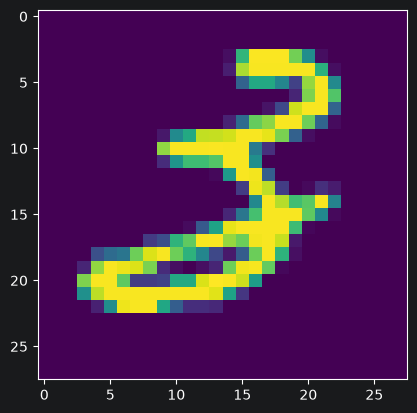

In [40]:
plt.imshow(x_test[false[1],:].reshape((28, 28)))